# APN 5

In [2]:
# markov_check.py    •   Python 3.11  •  NumPy ≥ 2.0
import json, math, sys
import numpy as np

FILE = "sboxes/data/apn_5.json"           # <-- put your JSON filename here
EPS  = 1e-12                   # tolerance for t_mix
KMAX = 32                      # evaluate up to 32 rounds

# ------------------------------------------------------------------ #
# 1) Load file (expecting a list[list[int]] of equal-length rows)
# ------------------------------------------------------------------ #
try:
    with open(FILE, "r", encoding="utf-8") as fh:
        tables = json.load(fh)
except Exception as e:
    sys.exit(f"Cannot read {FILE}: {e}")

if not tables:
    sys.exit("No S-Boxes found!")

N = len(tables[0])            # 32  (must be 2^n)
n = int(math.log2(N))
assert 2 ** n == N, "Table length must be a power of 2"

# ------------------------------------------------------------------ #
def is_bijective(t: list[int]) -> bool:
    return len(t) == N and len(set(t)) == N

def normalised_ddt(table: list[int]) -> np.ndarray:
    """Return (N-1)×(N-1) matrix with rows/cols 0 removed and ÷2ⁿ."""
    ddt = np.zeros((N, N), dtype=int)
    for x in range(N):
        for dx in range(N):
            dy = table[x] ^ table[x ^ dx]
            ddt[dx, dy] += 1
    return ddt[1:, 1:] / N     # normalise → probabilities

def markov_metrics(P: np.ndarray,
                   eps=EPS,
                   k_max=KMAX) -> tuple[int, float, float]:
    """Return (t_mix, max_prob, d_tv) or (k_max, …) if not mixed."""
    size = P.shape[0]                 # N-1
    pi   = np.full(size, 1/size)
    PK   = np.eye(size)
    for k in range(1, k_max + 1):
        PK = PK @ P
        d_tv = 0.5 * np.abs(PK - pi).sum(axis=1).max()
        max_p = PK.max()
        if d_tv <= eps:
            return k, max_p, d_tv
    return k_max, max_p, d_tv         # still not at eps

# ------------------------------------------------------------------ #
print(f"{'Idx':>3}  Bijective  t_mix  max P^k   d_TV")
print("-"*41)

for idx, tbl in enumerate(tables, 1):
    if not is_bijective(tbl):
        print(f"{idx:>3}     NO     –––     –––       –––   (skipped)")
        continue

    P = normalised_ddt(tbl)
    t_mix, mprob, d_tv = markov_metrics(P)
    print(f"{idx:>3}    YES   {t_mix:>5}  {mprob:>8.4f}  {d_tv:>8.2e}")


Idx  Bijective  t_mix  max P^k   d_TV
-----------------------------------------
  1    YES      17    0.0323  3.82e-13
  2    YES      17    0.0323  3.82e-13
  3    YES      17    0.0323  3.75e-13
  4    YES      17    0.0323  3.82e-13
  5    YES      17    0.0323  3.87e-13
  6    YES      17    0.0323  3.80e-13
  7    YES      17    0.0323  3.81e-13
  8    YES      17    0.0323  3.75e-13
  9    YES      17    0.0323  3.75e-13
 10    YES      17    0.0323  3.87e-13
 11    YES      17    0.0323  3.77e-13
 12    YES      17    0.0323  3.77e-13
 13    YES      17    0.0323  3.77e-13
 14    YES      17    0.0323  3.87e-13
 15    YES      17    0.0323  3.77e-13
 16    YES      17    0.0323  3.80e-13
 17    YES      17    0.0323  3.81e-13
 18    YES      17    0.0323  3.82e-13
 19    YES      17    0.0323  3.82e-13
 20    YES      17    0.0323  3.81e-13
 21    YES      17    0.0323  3.80e-13
 22    YES      17    0.0323  3.77e-13
 23    YES      17    0.0323  3.77e-13
 24    YES      17    0

In [3]:
from sboxes.loader import load as load_sbox
from evaluation.identity_sbox import IdentitySBox
from evaluation.markov_chains.all_test_markov_chains import (
    compare_tv_distance,
    compare_max_probability,
    compare_mixing_times
)
TABLEAU10 = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b", "#e377c2", "#7f7f7f", "#bcbd22", "#17becf"]
TABLEAU10 = ["#e41a1c","#377eb8","#4daf4a","#984ea3","#ff7f00","#ffff33","#a65628","#f781bf","#999999"]

import seaborn as sns

COLORS_FOR_OWNS = sns.color_palette("ch:s=.25,rot=-.25", n_colors=48) [::-1]
#sns.palplot(sns.color_palette("Reds", n_colors=10))[::-3]  # Colores para las S-Boxes propias
COLORS_FOR_CLASICS = sns.color_palette("Reds", n_colors=10)[::-3]


In [4]:
from evaluation.avalanche_criterion import avalanche_criterion
from evaluation.fixed_points import fixed_ponts
from evaluation.uniformity import get_ddt
from evaluation.linearity import evaluate
from sboxes.loader import load as load_sbox

to_proof = ["ascon", "fides_5_AB"]#"nuestro 5.v1", "nuestro 5.v2", "nuestro 5.v3"]

specs1 = []

for sbox_link in to_proof:
    sbox = load_sbox(f"sboxes/data/{sbox_link}.json")
    ddt = get_ddt(sbox)
    max_ddt = np.max(ddt[1:])        # ignoramos dx = 0
    uniformity = max_ddt
    fixed = fixed_ponts(sbox, detail=True)[1]
    non_linearities = evaluate(sbox)
    specs1.append({
        'name': sbox.name,
        'table': sbox.table.tolist(),
        'n_in': sbox.input_size,
        'n_out': sbox.output_size,
        'color': COLORS_FOR_CLASICS[len(specs1) % len(COLORS_FOR_CLASICS)],
        'sbox': sbox
        
    })
    print(f"Procesando S-Box: {sbox.name} ({sbox.input_size}x{sbox.output_size})")

0 -> 4
1 -> 11
2 -> 31
3 -> 20
4 -> 26
5 -> 21
6 -> 9
7 -> 2
8 -> 27
9 -> 5
10 -> 8
11 -> 18
12 -> 29
13 -> 3
14 -> 6
15 -> 28
16 -> 30
17 -> 19
18 -> 7
19 -> 14
20 -> 0
21 -> 13
22 -> 17
23 -> 24
24 -> 16
25 -> 12
26 -> 1
27 -> 25
28 -> 22
29 -> 10
30 -> 15
31 -> 23
Procesando S-Box: ASCON (5x5)
0 -> 1
1 -> 0
2 -> 25
3 -> 26
4 -> 17
5 -> 29
6 -> 21
7 -> 27
8 -> 20
9 -> 5
10 -> 4
11 -> 23
12 -> 14
13 -> 18
14 -> 2
15 -> 28
16 -> 15
17 -> 8
18 -> 6
19 -> 3
20 -> 13
21 -> 7
22 -> 24
23 -> 16
24 -> 30
25 -> 9
26 -> 31
27 -> 10
28 -> 22
29 -> 12
30 -> 11
31 -> 19
Procesando S-Box: FIDES_5 (5x5)


In [5]:
import json
from sboxes import SBox

specs2 = []
# ---------- 1. Cargar el JSON ----------
with open("sboxes/data/apn_5.json"  , "r", encoding="utf-8") as f:
    data = json.load(f)

# ---------- 2. Procesar cada S-Box ----------
for idx, sb in enumerate(data, 1):
 
    print(sb)        
    table = list(map(lambda x: hex(x), sb))                   # lista de enteros
    n_in  = 5           # nº de bits de entrada
    n_out = 5  # nº de bits de salida
    name = f"apn #{idx}"
    biggest_possible_output = 1 << n_out
    final_table = np.empty(len(table), dtype=np.uint64)
    for idx, i in enumerate(table):#sb["table"]):
        output = int(i, 0)
        if output > biggest_possible_output or output < 0:
            raise ValueError("Table values must be greater than or equal to 0 and less than or equal to 2^%d" % n_out)
        final_table[idx] = output
        
    sbox = SBox(n_in, n_out, final_table, name)                      # <- ajusta a tu clase
    print("size:",len(sb))
    specs2.append({
        "name": name,              # pon aquí el nombre que prefieras
        "table": sbox.table.tolist(),
        "n_in": n_in,
        "n_out": n_out,
        "color": COLORS_FOR_OWNS[len(specs2) % len(COLORS_FOR_OWNS)],
        "sbox":  sbox
    })

# ---------- 3. (Opcional) comprobar ----------
print(f"{len(specs2)} S-Boxes cargadas desde data.json")
for s in specs2:
    print(s["name"], "–", s["n_in"], "→", s["n_out"])

[16, 24, 7, 13, 3, 6, 8, 15, 19, 11, 12, 22, 10, 31, 9, 30, 27, 21, 29, 17, 26, 25, 0, 1, 28, 2, 18, 14, 23, 4, 5, 20]
size: 32
[27, 21, 29, 17, 26, 25, 0, 1, 28, 2, 18, 14, 23, 4, 5, 20, 16, 24, 7, 13, 3, 6, 8, 15, 19, 11, 12, 22, 10, 31, 9, 30]
size: 32
[19, 11, 12, 22, 10, 31, 9, 30, 28, 2, 18, 14, 23, 4, 5, 20, 16, 24, 7, 13, 3, 6, 8, 15, 27, 21, 29, 17, 26, 25, 0, 1]
size: 32
[1, 0, 25, 26, 17, 29, 21, 27, 20, 5, 4, 23, 14, 18, 2, 28, 15, 8, 6, 3, 13, 7, 24, 16, 30, 9, 31, 10, 22, 12, 11, 19]
size: 32
[28, 2, 18, 14, 23, 4, 5, 20, 16, 24, 7, 13, 3, 6, 8, 15, 27, 21, 29, 17, 26, 25, 0, 1, 19, 11, 12, 22, 10, 31, 9, 30]
size: 32
[30, 9, 31, 10, 22, 12, 11, 19, 20, 5, 4, 23, 14, 18, 2, 28, 1, 0, 25, 26, 17, 29, 21, 27, 15, 8, 6, 3, 13, 7, 24, 16]
size: 32
[20, 5, 4, 23, 14, 18, 2, 28, 1, 0, 25, 26, 17, 29, 21, 27, 15, 8, 6, 3, 13, 7, 24, 16, 30, 9, 31, 10, 22, 12, 11, 19]
size: 32
[16, 24, 7, 13, 3, 6, 8, 15, 27, 21, 29, 17, 26, 25, 0, 1, 19, 11, 12, 22, 10, 31, 9, 30, 28, 2, 18, 14,

In [6]:
specs = specs1 + specs2

|   r |    ASCON |   FIDES_5 |   apn #1 |   apn #2 |   apn #3 |   apn #4 |   apn #5 |   apn #6 |   apn #7 |   apn #8 |   apn #9 |   apn #10 |   apn #11 |   apn #12 |   apn #13 |   apn #14 |   apn #15 |   apn #16 |   apn #17 |   apn #18 |   apn #19 |   apn #20 |   apn #21 |   apn #22 |   apn #23 |   apn #24 |   apn #25 |   apn #26 |   apn #27 |   apn #28 |   apn #29 |   apn #30 |   apn #31 |   apn #32 |   apn #33 |   apn #34 |   apn #35 |   apn #36 |   apn #37 |   apn #38 |   apn #39 |   apn #40 |   apn #41 |   apn #42 |   apn #43 |   apn #44 |   apn #45 |   apn #46 |   apn #47 |   apn #48 |
|-----|----------|-----------|----------|----------|----------|----------|----------|----------|----------|----------|----------|-----------|-----------|-----------|-----------|-----------|-----------|-----------|-----------|-----------|-----------|-----------|-----------|-----------|-----------|-----------|-----------|-----------|-----------|-----------|-----------|-----------|-----------|---------

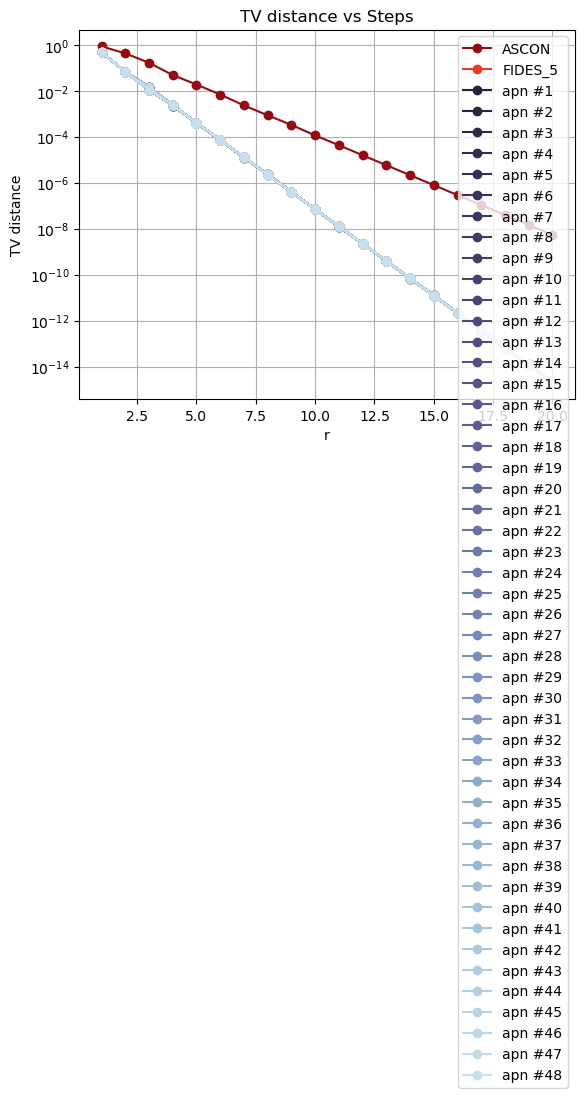

In [7]:
 # Comparaciones
ans = compare_tv_distance(specs, detail=True, graphic=True, log_scale=1)

|   r |    ASCON |   FIDES_5 |   apn #1 |   apn #2 |   apn #3 |   apn #4 |   apn #5 |   apn #6 |   apn #7 |   apn #8 |   apn #9 |   apn #10 |   apn #11 |   apn #12 |   apn #13 |   apn #14 |   apn #15 |   apn #16 |   apn #17 |   apn #18 |   apn #19 |   apn #20 |   apn #21 |   apn #22 |   apn #23 |   apn #24 |   apn #25 |   apn #26 |   apn #27 |   apn #28 |   apn #29 |   apn #30 |   apn #31 |   apn #32 |   apn #33 |   apn #34 |   apn #35 |   apn #36 |   apn #37 |   apn #38 |   apn #39 |   apn #40 |   apn #41 |   apn #42 |   apn #43 |   apn #44 |   apn #45 |   apn #46 |   apn #47 |   apn #48 |
|-----|----------|-----------|----------|----------|----------|----------|----------|----------|----------|----------|----------|-----------|-----------|-----------|-----------|-----------|-----------|-----------|-----------|-----------|-----------|-----------|-----------|-----------|-----------|-----------|-----------|-----------|-----------|-----------|-----------|-----------|-----------|---------

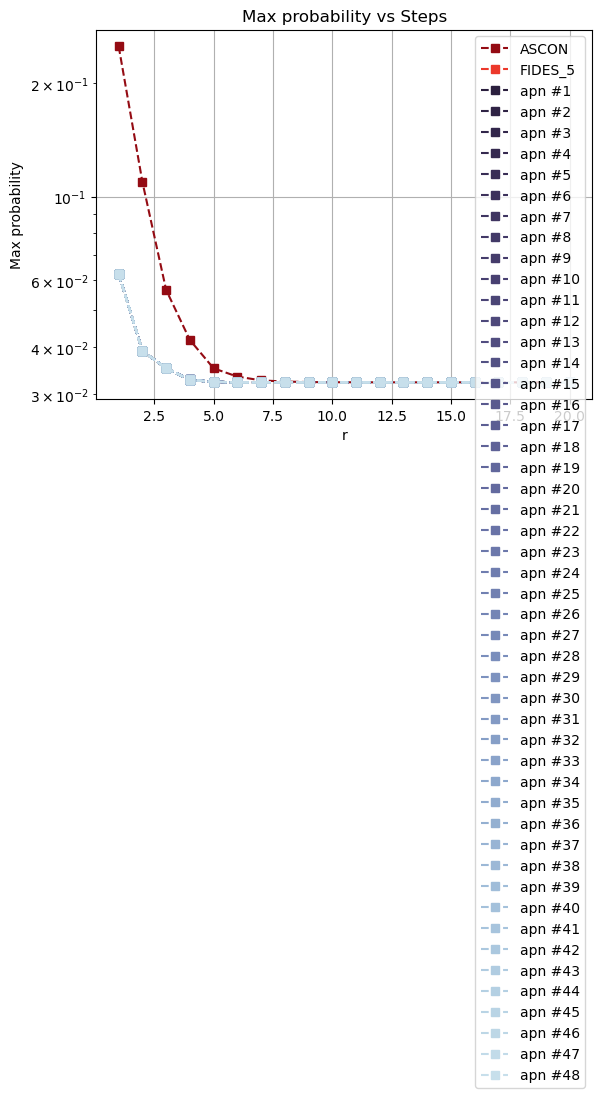

In [8]:
ans = compare_max_probability(specs, detail=True, graphic=True, log_scale=True)


|      ε |   ASCON iter |   FIDES_5 iter |   apn #1 iter |   apn #2 iter |   apn #3 iter |   apn #4 iter |   apn #5 iter |   apn #6 iter |   apn #7 iter |   apn #8 iter |   apn #9 iter |   apn #10 iter |   apn #11 iter |   apn #12 iter |   apn #13 iter |   apn #14 iter |   apn #15 iter |   apn #16 iter |   apn #17 iter |   apn #18 iter |   apn #19 iter |   apn #20 iter |   apn #21 iter |   apn #22 iter |   apn #23 iter |   apn #24 iter |   apn #25 iter |   apn #26 iter |   apn #27 iter |   apn #28 iter |   apn #29 iter |   apn #30 iter |   apn #31 iter |   apn #32 iter |   apn #33 iter |   apn #34 iter |   apn #35 iter |   apn #36 iter |   apn #37 iter |   apn #38 iter |   apn #39 iter |   apn #40 iter |   apn #41 iter |   apn #42 iter |   apn #43 iter |   apn #44 iter |   apn #45 iter |   apn #46 iter |   apn #47 iter |   apn #48 iter |   ASCON spec |   FIDES_5 spec |   apn #1 spec |   apn #2 spec |   apn #3 spec |   apn #4 spec |   apn #5 spec |   apn #6 spec |   apn #7 spec |   apn 

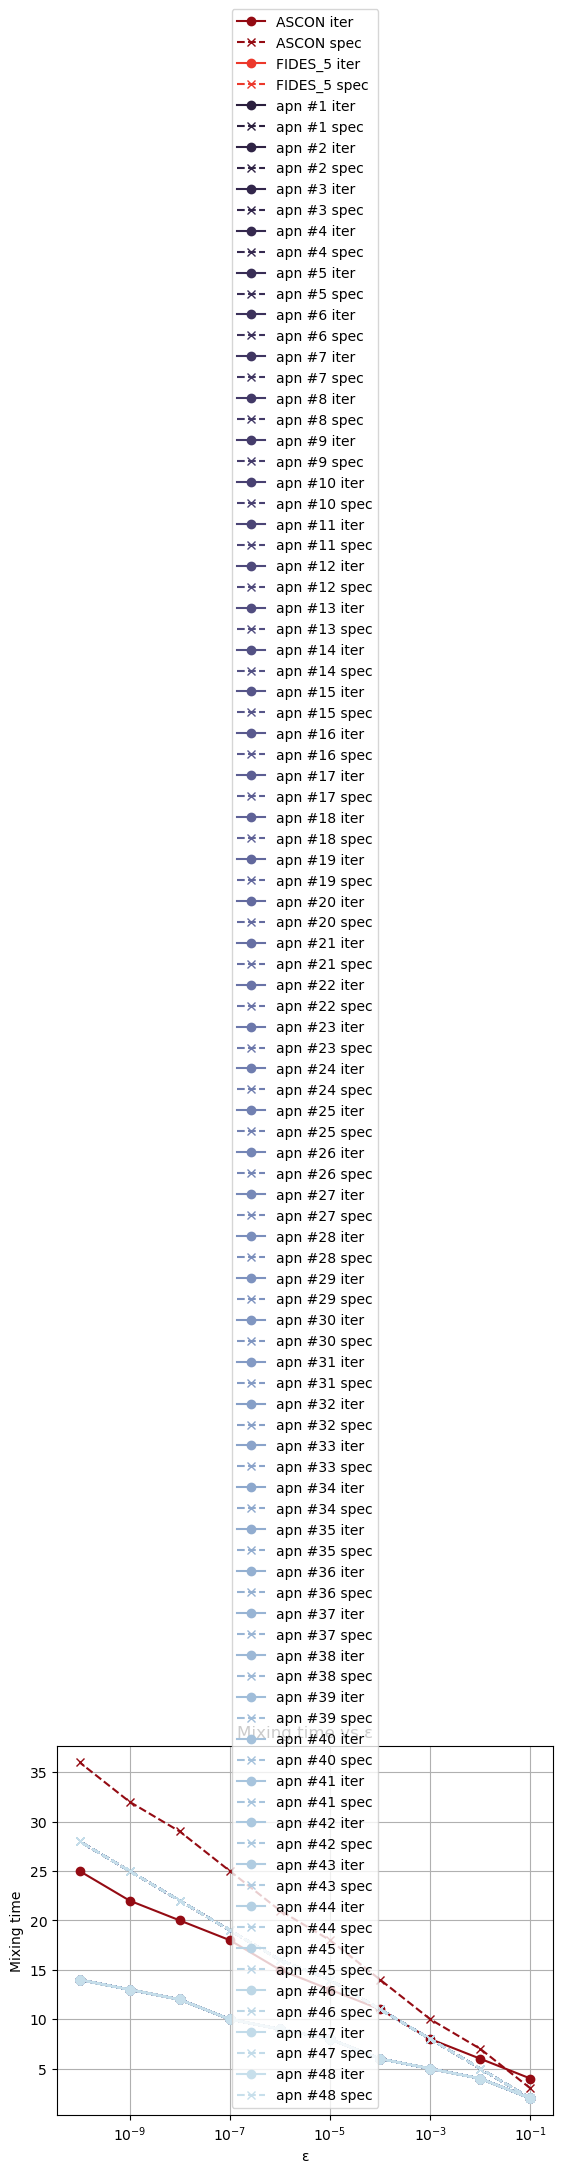

In [9]:
ans = compare_mixing_times(specs, detail=True, graphic=True, log_scale=True)    

0 -> 4
1 -> 11
2 -> 31
3 -> 20
4 -> 26
5 -> 21
6 -> 9
7 -> 2
8 -> 27
9 -> 5
10 -> 8
11 -> 18
12 -> 29
13 -> 3
14 -> 6
15 -> 28
16 -> 30
17 -> 19
18 -> 7
19 -> 14
20 -> 0
21 -> 13
22 -> 17
23 -> 24
24 -> 16
25 -> 12
26 -> 1
27 -> 25
28 -> 22
29 -> 10
30 -> 15
31 -> 23
0 -> 1
1 -> 0
2 -> 25
3 -> 26
4 -> 17
5 -> 29
6 -> 21
7 -> 27
8 -> 20
9 -> 5
10 -> 4
11 -> 23
12 -> 14
13 -> 18
14 -> 2
15 -> 28
16 -> 15
17 -> 8
18 -> 6
19 -> 3
20 -> 13
21 -> 7
22 -> 24
23 -> 16
24 -> 30
25 -> 9
26 -> 31
27 -> 10
28 -> 22
29 -> 12
30 -> 11
31 -> 19
0 -> 16
1 -> 24
2 -> 7
3 -> 13
4 -> 3
5 -> 6
6 -> 8
7 -> 15
8 -> 19
9 -> 11
10 -> 12
11 -> 22
12 -> 10
13 -> 31
14 -> 9
15 -> 30
16 -> 27
17 -> 21
18 -> 29
19 -> 17
20 -> 26
21 -> 25
22 -> 0
23 -> 1
24 -> 28
25 -> 2
26 -> 18
27 -> 14
28 -> 23
29 -> 4
30 -> 5
31 -> 20
0 -> 27
1 -> 21
2 -> 29
3 -> 17
4 -> 26
5 -> 25
6 -> 0
7 -> 1
8 -> 28
9 -> 2
10 -> 18
11 -> 14
12 -> 23
13 -> 4
14 -> 5
15 -> 20
16 -> 16
17 -> 24
18 -> 7
19 -> 13
20 -> 3
21 -> 6
22 -> 8
23 -> 15

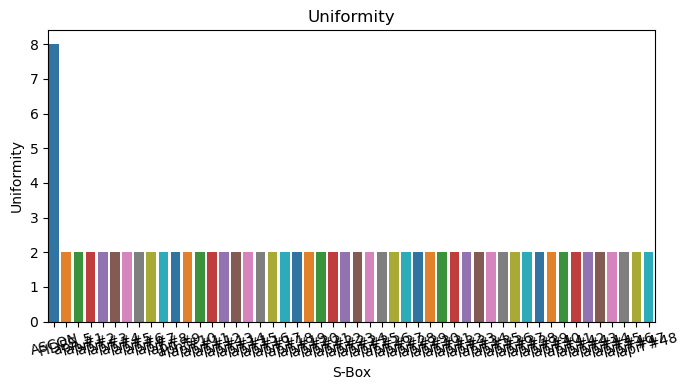

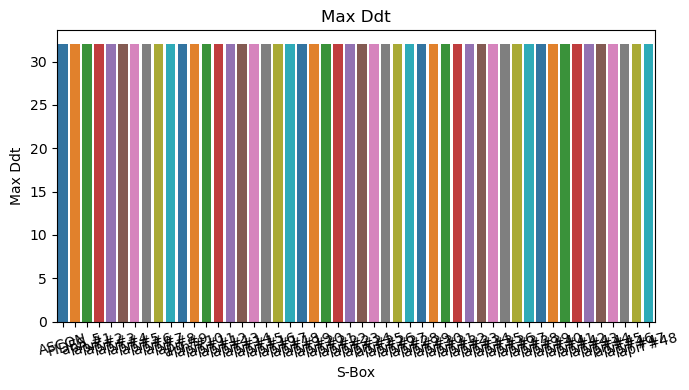

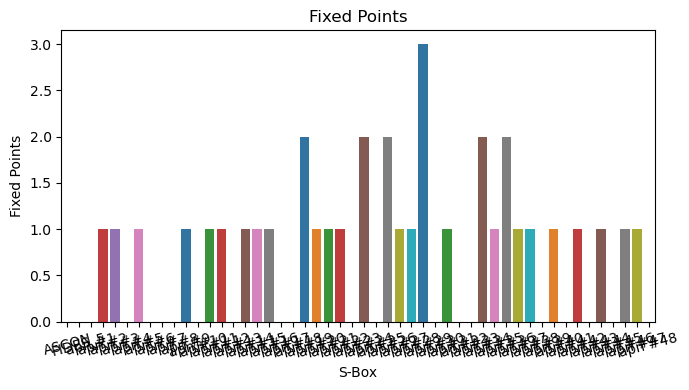

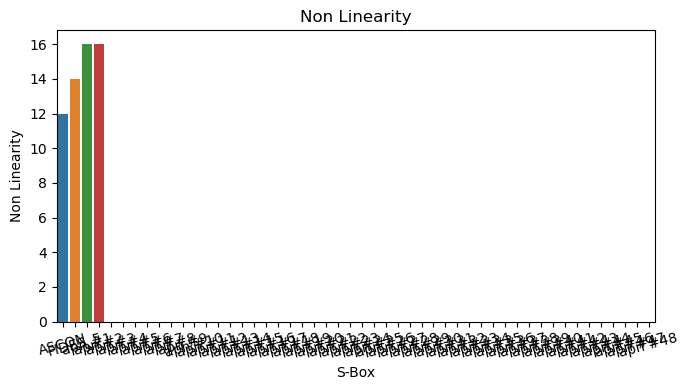

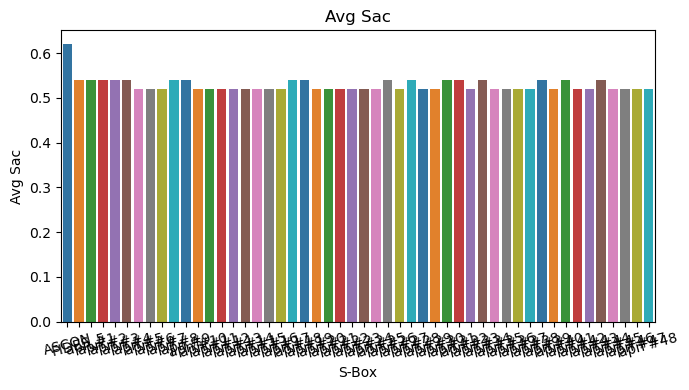

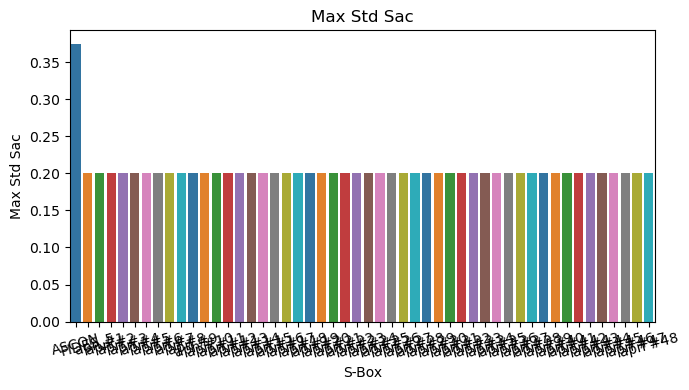

,name,uniformity,max_ddt,fixed_points,non_linearity,avg_sac,max_std_sac
0,ASCON,8,32,0,12.0,0.62,0.374166
1,FIDES_5,2,32,0,14.0,0.54,0.200000
2,apn #1,2,32,0,16.0,0.54,0.200000
3,apn #2,2,32,1,16.0,0.54,0.200000
4,apn #3,2,32,1,NaN,0.54,0.200000
5,apn #4,2,32,0,NaN,0.54,0.200000
6,apn #5,2,32,1,NaN,0.52,0.200000
7,apn #6,2,32,0,NaN,0.52,0.200000
8,apn #7,2,32,0,NaN,0.52,0.200000
9,apn #8,2,32,0,NaN,0.54,0.200000


In [10]:
from evaluation.sbox_metrics_analysis import run_all_metrics

# Define specs (como ya haces) y tus valores de no-linealidad:
non_linearities = [12, 14, 16, 16]  # valores que tú determines
run_all_metrics(specs, non_linearities)

In [ ]:
sb = [0,1,2,3,4,6,7]

specs5 = []
print(sb)        
table = list(map(lambda x: hex(x), sb))                   # lista de enteros
n_in  = 3           # nº de bits de entrada
n_out = 3  # nº de bits de salida
name = f"example"
biggest_possible_output = 1 << n_out
final_table = np.empty(len(table), dtype=np.uint64)
for idx, i in enumerate(table):#sb["table"]):
    output = int(i, 0)
    if output > biggest_possible_output or output < 0:
        raise ValueError("Table values must be greater than or equal to 0 and less than or equal to 2^%d" % n_out)
    final_table[idx] = output
    
sbox = SBox(n_in, n_out, final_table, name)                      # <- ajusta a tu clase
print("size:",len(sb))
specs5.append({
    "name": name,              # pon aquí el nombre que prefieras
    "table": sbox.table.tolist(),
    "n_in": n_in,
    "n_out": n_out,
    "color": COLORS_FOR_OWNS[len(specs2) % len(COLORS_FOR_OWNS)],
    "sbox":  sbox
})

print(specs5)
ddt = get_ddt(sbox)

print(ddt)


[0, 1, 2, 3, 4, 6, 7]
size: 7
[{'name': 'example', 'table': [0, 1, 2, 3, 4, 6, 7], 'n_in': 5, 'n_out': 5, 'color': (0.2476321504153338, 0.20845115755139962, 0.38127234337438914), 'sbox': <numba.experimental.jitclass.boxing.SBox object at 0x000001F6250D1330>}]


AssertionError: 